***UCS-420 ASSIGNMENT 8***

Q1.

In [1]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from collections import Counter

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [2]:
text = """Lionel Messi is widely regarded as one of the greatest footballers the world has ever seen. He spent nearly two decades representing Argentina, carrying the weight of a nation's expectations on his shoulders. His legacy was sealed when he captained Argentina to World Cup glory in Qatar in 2022, adding to the Copa America titles he won in 2021 and 2024. In 2026 he led his team to another World Cup final, though Argentina lost to Spain. Soon after, at the age of 39, Messi announced his retirement from the national team, leaving as Argentina's all-time leading scorer. His career has inspired millions of fans and young players, and his name will always be remembered in football history."""
print(text)

Lionel Messi is widely regarded as one of the greatest footballers the world has ever seen. He spent nearly two decades representing Argentina, carrying the weight of a nation's expectations on his shoulders. His legacy was sealed when he captained Argentina to World Cup glory in Qatar in 2022, adding to the Copa America titles he won in 2021 and 2024. In 2026 he led his team to another World Cup final, though Argentina lost to Spain. Soon after, at the age of 39, Messi announced his retirement from the national team, leaving as Argentina's all-time leading scorer. His career has inspired millions of fans and young players, and his name will always be remembered in football history.


lionel messi is widely regarded as one of the greatest footballers the world has ever seen he spent nearly two decades representing argentina carrying the weight of a nations expectations on his shoulders his legacy was sealed when he captained argentina to world cup glory in qatar in 2022 adding to the copa america titles he won in 2021 and 2024 in 2026 he led his team to another world cup final though argentina lost to spain soon after at the age of 39 messi announced his retirement from the national team leaving as argentinas alltime leading scorer his career has inspired millions of fans and young players and his name will always be remembered in football history
6 ['Lionel Messi is widely regarded as one of the greatest footballers the world has ever seen.', "He spent nearly two decades representing Argentina, carrying the weight of a nation's expectations on his shoulders.", 'His legacy was sealed when he captained Argentina to World Cup glory in Qatar in 2022, adding to the Copa

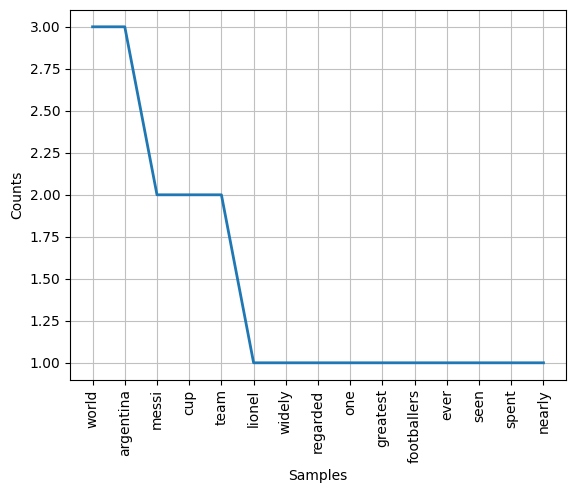

In [3]:
clean_text = text.lower()
clean_text = re.sub(r'[^\w\s]', '', clean_text)
print(clean_text)

sentences = sent_tokenize(text)
words = word_tokenize(clean_text)
print(len(sentences), sentences)
print(len(words), words)

split_tokens = text.lower().split()
nltk_tokens = word_tokenize(text.lower())
print(len(split_tokens), split_tokens)
print(len(nltk_tokens), nltk_tokens)
print(set(split_tokens) - set(nltk_tokens))
print(set(nltk_tokens) - set(split_tokens))

stop_words = set(stopwords.words('english'))
filtered = [w for w in words if w not in stop_words]
print(len(filtered), filtered)

import matplotlib.pyplot as plt
fdist = nltk.FreqDist(filtered)
print(fdist.most_common(10))
fdist.plot(15)
plt.show()

Q2.

In [4]:
from nltk.stem import PorterStemmer, WordNetLemmatizer

alpha_words = re.findall(r'[a-zA-Z]+', text.lower())
print(len(alpha_words), alpha_words)

stop_words = set(stopwords.words('english'))
filtered = [w for w in alpha_words if w not in stop_words]
print(len(filtered), filtered)

ps = PorterStemmer()
stemmed = [ps.stem(w) for w in filtered]
print(stemmed)

wl = WordNetLemmatizer()
lemmatized = [wl.lemmatize(w) for w in filtered]
print(lemmatized)

import pandas as pd
df = pd.DataFrame({'original': filtered, 'stemmed': stemmed, 'lemmatized': lemmatized})
print(df[df['stemmed'] != df['lemmatized']])

116 ['lionel', 'messi', 'is', 'widely', 'regarded', 'as', 'one', 'of', 'the', 'greatest', 'footballers', 'the', 'world', 'has', 'ever', 'seen', 'he', 'spent', 'nearly', 'two', 'decades', 'representing', 'argentina', 'carrying', 'the', 'weight', 'of', 'a', 'nation', 's', 'expectations', 'on', 'his', 'shoulders', 'his', 'legacy', 'was', 'sealed', 'when', 'he', 'captained', 'argentina', 'to', 'world', 'cup', 'glory', 'in', 'qatar', 'in', 'adding', 'to', 'the', 'copa', 'america', 'titles', 'he', 'won', 'in', 'and', 'in', 'he', 'led', 'his', 'team', 'to', 'another', 'world', 'cup', 'final', 'though', 'argentina', 'lost', 'to', 'spain', 'soon', 'after', 'at', 'the', 'age', 'of', 'messi', 'announced', 'his', 'retirement', 'from', 'the', 'national', 'team', 'leaving', 'as', 'argentina', 's', 'all', 'time', 'leading', 'scorer', 'his', 'career', 'has', 'inspired', 'millions', 'of', 'fans', 'and', 'young', 'players', 'and', 'his', 'name', 'will', 'always', 'be', 'remembered', 'in', 'football', 'h

Prefer **stemming** when speed matters and exact word form doesn’t, such as search engines, information retrieval or large-scale text classification, where play, plays and playing just need to match whereas
prefer **lemmatization** when the output must be a proper word and meaning matters, such as sentiment analysis, chatbots, question answering or text generation.

Q3.

In [5]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd
import numpy as np

texts = [
    "Messi announces retirement from the Argentina national team after leading Argentina to the World Cup final.",
    "Dhruv Rathee's video on the protest sparks debate online as thousands of viewers share opinions about the protest.",
    "Fans are excited for Avengers Doomsday as the trailer breaks records and Marvel promises a huge Avengers crossover."
]

cv = CountVectorizer(stop_words='english')
bow = cv.fit_transform(texts)
bow_df = pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out(), index=['Text1', 'Text2', 'Text3'])
print(bow_df)

tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(texts)
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf.get_feature_names_out(), index=['Text1', 'Text2', 'Text3'])
print(tfidf_df.round(3))

features = tfidf.get_feature_names_out()
for i in range(len(texts)):
    scores = tfidf_matrix[i].toarray()[0]
    top3 = np.argsort(scores)[::-1][:3]
    print(f"Text {i+1} top 3 keywords:")
    for j in top3:
        print(features[j], round(scores[j], 3))

       announces  argentina  avengers  breaks  crossover  cup  debate  dhruv  \
Text1          1          2         0       0          0    1       0      0   
Text2          0          0         0       0          0    0       1      1   
Text3          0          0         2       1          1    0       0      0   

       doomsday  excited  ...  records  retirement  share  sparks  team  \
Text1         0        0  ...        0           1      0       0     1   
Text2         0        0  ...        0           0      1       1     0   
Text3         1        1  ...        1           0      0       0     0   

       thousands  trailer  video  viewers  world  
Text1          0        0      0        0      1  
Text2          1        0      1        1      0  
Text3          0        1      0        0      0  

[3 rows x 32 columns]
       announces  argentina  avengers  breaks  crossover    cup  debate  \
Text1      0.277      0.555     0.000   0.000      0.000  0.277   0.000   
T

Q4.

In [6]:
import re
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text_ai = """Artificial intelligence allows machines to learn from data and make decisions without being explicitly programmed.
It powers applications like chatbots, image recognition and recommendation systems.
Machine learning models improve their accuracy as they are trained on more data.
AI is widely used in healthcare, finance and education to automate tasks and predict outcomes.
Companies invest heavily in AI to save time and improve efficiency."""

text_bc = """Blockchain is a decentralized digital ledger that records transactions across many computers.
Each block is linked to the previous one using cryptography, which makes the data very hard to alter.
It removes the need for a central authority like a bank to verify transactions.
Blockchain is used in cryptocurrencies, supply chain tracking and secure data sharing.
Its main strengths are transparency, security and trust between users."""

stop_words = set(stopwords.words('english'))

def preprocess(t):
    t = t.lower()
    t = re.sub(r'[^\w\s]', '', t)
    tokens = word_tokenize(t)
    return [w for w in tokens if w not in stop_words]

tokens_ai = preprocess(text_ai)
tokens_bc = preprocess(text_bc)
print(tokens_ai)
print(tokens_bc)

set_ai = set(tokens_ai)
set_bc = set(tokens_bc)
intersection = set_ai & set_bc
union = set_ai | set_bc
jaccard = len(intersection) / len(union)
print("Common words:", intersection)
print("Jaccard Similarity:", round(jaccard, 4))

clean_ai = " ".join(tokens_ai)
clean_bc = " ".join(tokens_bc)
tfidf = TfidfVectorizer()
matrix = tfidf.fit_transform([clean_ai, clean_bc])
cos_sim = cosine_similarity(matrix[0], matrix[1])[0][0]
print("Cosine Similarity:", round(cos_sim, 4))

['artificial', 'intelligence', 'allows', 'machines', 'learn', 'data', 'make', 'decisions', 'without', 'explicitly', 'programmed', 'powers', 'applications', 'like', 'chatbots', 'image', 'recognition', 'recommendation', 'systems', 'machine', 'learning', 'models', 'improve', 'accuracy', 'trained', 'data', 'ai', 'widely', 'used', 'healthcare', 'finance', 'education', 'automate', 'tasks', 'predict', 'outcomes', 'companies', 'invest', 'heavily', 'ai', 'save', 'time', 'improve', 'efficiency']
['blockchain', 'decentralized', 'digital', 'ledger', 'records', 'transactions', 'across', 'many', 'computers', 'block', 'linked', 'previous', 'one', 'using', 'cryptography', 'makes', 'data', 'hard', 'alter', 'removes', 'need', 'central', 'authority', 'like', 'bank', 'verify', 'transactions', 'blockchain', 'used', 'cryptocurrencies', 'supply', 'chain', 'tracking', 'secure', 'data', 'sharing', 'main', 'strengths', 'transparency', 'security', 'trust', 'users']
Common words: {'used', 'like', 'data'}
Jaccard 

**Jaccard similarity** only checks which words appear in both texts, ignoring how often they appear, so it treats every shared word as equally important. Here it comes out very low because the two texts share only a few words, such as data.


**Cosine similarity** with TF-IDF compares the weighted word vectors, so it accounts for word frequency and downweights common words while highlighting distinctive ones. It comes out low as well, since the topics are different.


Better metric: cosine similarity with TF-IDF gives better insight in this case.
Jaccard is still useful as a quick, simple check of vocabulary overlap, but for comparing meaning and topic, cosine with TF-IDF is stronger.

Q5.

                                                                                     review  polarity  subjectivity sentiment
0     This phone is amazing, the battery lasts all day and the camera quality is excellent.     0.800         0.950  Positive
1   Terrible experience, the delivery was late and the product stopped working in two days.    -0.650         0.800  Negative
2                             The headphones are okay, nothing special but they do the job.     0.429         0.536  Positive
3        Absolutely love this laptop, super fast, smooth display and great value for money.     0.447         0.623  Positive
4              Very disappointing, the build quality is poor and customer support was rude.    -0.493         0.703  Negative
5             Great service, the staff was friendly and the food arrived hot and delicious.     0.606         0.775  Positive
6  The shoes are average, comfortable enough but the color looks different from the photos.     0.062         0.575   

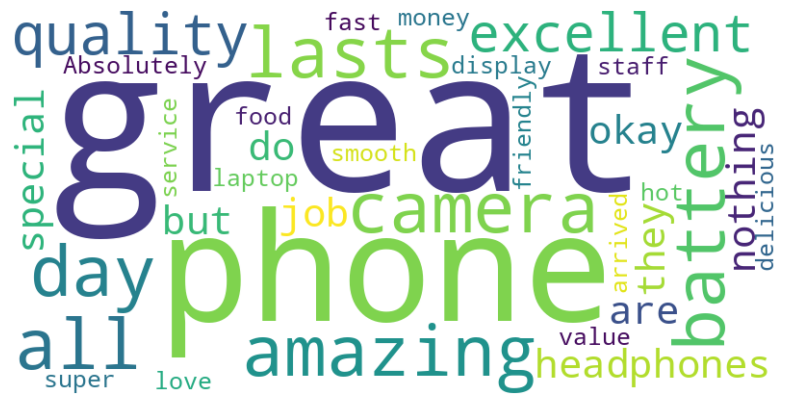

In [7]:
!pip install textblob wordcloud -q

from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import pandas as pd

reviews = [
    "This phone is amazing, the battery lasts all day and the camera quality is excellent.",
    "Terrible experience, the delivery was late and the product stopped working in two days.",
    "The headphones are okay, nothing special but they do the job.",
    "Absolutely love this laptop, super fast, smooth display and great value for money.",
    "Very disappointing, the build quality is poor and customer support was rude.",
    "Great service, the staff was friendly and the food arrived hot and delicious.",
    "The shoes are average, comfortable enough but the color looks different from the photos."
]

results = []
for r in reviews:
    blob = TextBlob(r)
    pol = blob.sentiment.polarity
    sub = blob.sentiment.subjectivity
    if pol > 0.1:
        label = "Positive"
    elif pol < -0.1:
        label = "Negative"
    else:
        label = "Neutral"
    results.append([r, round(pol, 3), round(sub, 3), label])

df = pd.DataFrame(results, columns=['review', 'polarity', 'subjectivity', 'sentiment'])
print(df.to_string())
print(df['sentiment'].value_counts())

positive_text = " ".join(df[df['sentiment'] == 'Positive']['review'])
wc = WordCloud(width=800, height=400, background_color='white', stopwords=set(['the', 'and', 'is', 'a', 'of', 'for', 'was', 'this'])).generate(positive_text)
plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.show()